# Notebook 3 — Quantum vibrational levels on a computed curve

**Session 1, about 50 minutes**

The harmonic frequency from a curvature is not what a spectrometer measures. Real bonds are
**anharmonic**: they get softer as they stretch and eventually break. The CO fundamental is
observed at **2143 cm⁻¹**, about 27 cm⁻¹ below the harmonic value $\omega_e$ = 2170 cm⁻¹.

Here you solve the vibrational Schrödinger equation **exactly on a grid** for the CCSD(T) curve from
Notebook 2:

$$\left[-\frac{\hbar^2}{2\mu}\frac{d^2}{dr^2} + V(r)\right]\psi_v(r) = E_v\,\psi_v(r)$$

### The finite-difference method
Put $r$ on an evenly spaced grid $r_i$ with spacing $h$. The second derivative becomes

$$\psi''(r_i) \approx \frac{\psi_{i+1} - 2\psi_i + \psi_{i-1}}{h^2},$$

so the Hamiltonian becomes a matrix: $V(r_i)$ on the diagonal, plus a kinetic part with $2t$ on the
diagonal and $-t$ on the two neighbouring diagonals, where $t = \hbar^2/(2\mu h^2)$.
Its eigenvalues are the energy levels and its eigenvectors are the wavefunctions.

In [1]:
import sys, os
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
import labkit as lk

fname = "co_ccsdt_curve.npz" if os.path.exists("co_ccsdt_curve.npz") else lk.data_path("co_ccsdt_curve.npz")
d = np.load(fname)
r_pts, V_pts, mu_pts = d["r"], d["E_eV"], d["mu_D"]
print("loaded", fname, "with", len(r_pts), "points")

m_C, m_O = lk.MASS["C"], lk.MASS["O"]
mu_CO = m_C * m_O / (m_C + m_O)

loaded co_ccsdt_curve.npz with 29 points


## 1. A smooth potential
The grid needs $V$ at many more points than we computed. A **cubic spline** passes smoothly through
the computed points.

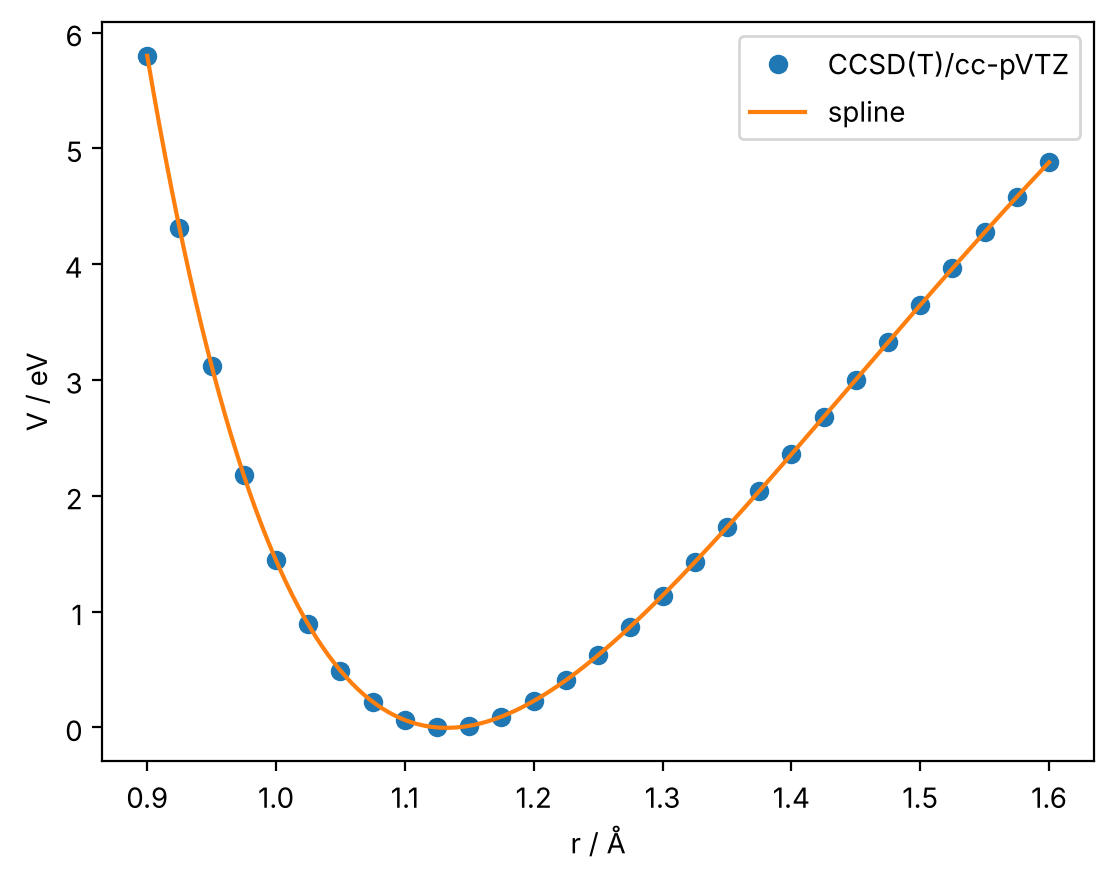

In [2]:
V = CubicSpline(r_pts, V_pts)
mu_of_r = CubicSpline(r_pts, mu_pts)
r_plot = np.linspace(r_pts[0], r_pts[-1], 300)
plt.plot(r_pts, V_pts, "o", label="CCSD(T)/cc-pVTZ"); plt.plot(r_plot, V(r_plot), label="spline")
plt.xlabel("r / Å"); plt.ylabel("V / eV"); plt.legend(); plt.show()

## 2. Units for the kinetic energy
With $\hbar$ in eV·fs (`lk.HBAR_EV_FS`), $\mu$ in amu and lengths in Å, the combination
$\hbar^2/\mu$ needs the same conversion factor as Newton's law: 1 amu·Å²/fs² = 1/`lk.ACC` eV. So

$$\frac{\hbar^2}{2\mu}\ [\text{eV·Å}^2] = \frac{\hbar^2\,[\text{eV}^2\text{fs}^2]\times \texttt{ACC}}{2\,\mu\,[\text{amu}]}.$$

**Exercise 1.** Write `vib_levels(V, mu, r_min, r_max, n)` that builds the finite-difference
Hamiltonian, diagonalises it with `np.linalg.eigh`, and returns the grid, the energies (eV) and the
wavefunctions (columns, normalised so that $\sum_i |\psi_i|^2 h = 1$).

In [3]:
def vib_levels(V, mu, r_min=0.90, r_max=1.60, n=600):
    """Finite-difference vibrational levels of a diatomic with potential V(r) (eV) and reduced mass mu (amu)."""
    r = np.linspace(r_min, r_max, n)
    h = r[1] - r[0]
    t = lk.HBAR_EV_FS**2 * lk.ACC / (2 * mu * h**2)
    H = np.diag(V(r) + 2 * t) - t * np.eye(n, k=1) - t * np.eye(n, k=-1)
    E, psi = np.linalg.eigh(H)
    psi = psi / np.sqrt(h)
    return r, E, psi

r, E, psi = vib_levels(V, mu_CO)
wn = (E - E[0]) * lk.EV_TO_CM1
print("zero-point energy  = %.0f cm^-1" % ((E[0] - V_pts.min()) * lk.EV_TO_CM1))
for v in range(1, 5):
    print(f"E({v}) - E(0) = {wn[v]:7.1f} cm^-1    E({v}) - E({v-1}) = {wn[v] - wn[v-1]:6.1f} cm^-1")

zero-point energy  = 1055 cm^-1
E(1) - E(0) =  2145.4 cm^-1    E(1) - E(0) = 2145.4 cm^-1
E(2) - E(0) =  4264.8 cm^-1    E(2) - E(1) = 2119.4 cm^-1
E(3) - E(0) =  6358.2 cm^-1    E(3) - E(2) = 2093.4 cm^-1
E(4) - E(0) =  8425.7 cm^-1    E(4) - E(3) = 2067.5 cm^-1


In [4]:
# check the method on a harmonic oscillator, where E_v = hbar*omega*(v + 1/2) exactly
k_test = 120.0
_, E_h, _ = vib_levels(lambda x: 0.5 * k_test * (x - 1.13)**2, mu_CO)
hw = lk.HBAR_EV_FS * np.sqrt(k_test / mu_CO * lk.ACC)
assert np.allclose(E_h[:4] / hw, [0.5, 1.5, 2.5, 3.5], atol=2e-3), E_h[:4] / hw
print("harmonic test passes: E_v / hbar*omega =", np.round(E_h[:4] / hw, 4))

harmonic test passes: E_v / hbar*omega = [0.5    1.4999 2.4998 3.4995]


## 3. Wavefunctions on the potential
**Exercise 2.** Plot $V(r)$ and, for $v$ = 0–4, draw each wavefunction offset vertically by its energy
(scale it so it is visible). Mark where the classical turning points are.

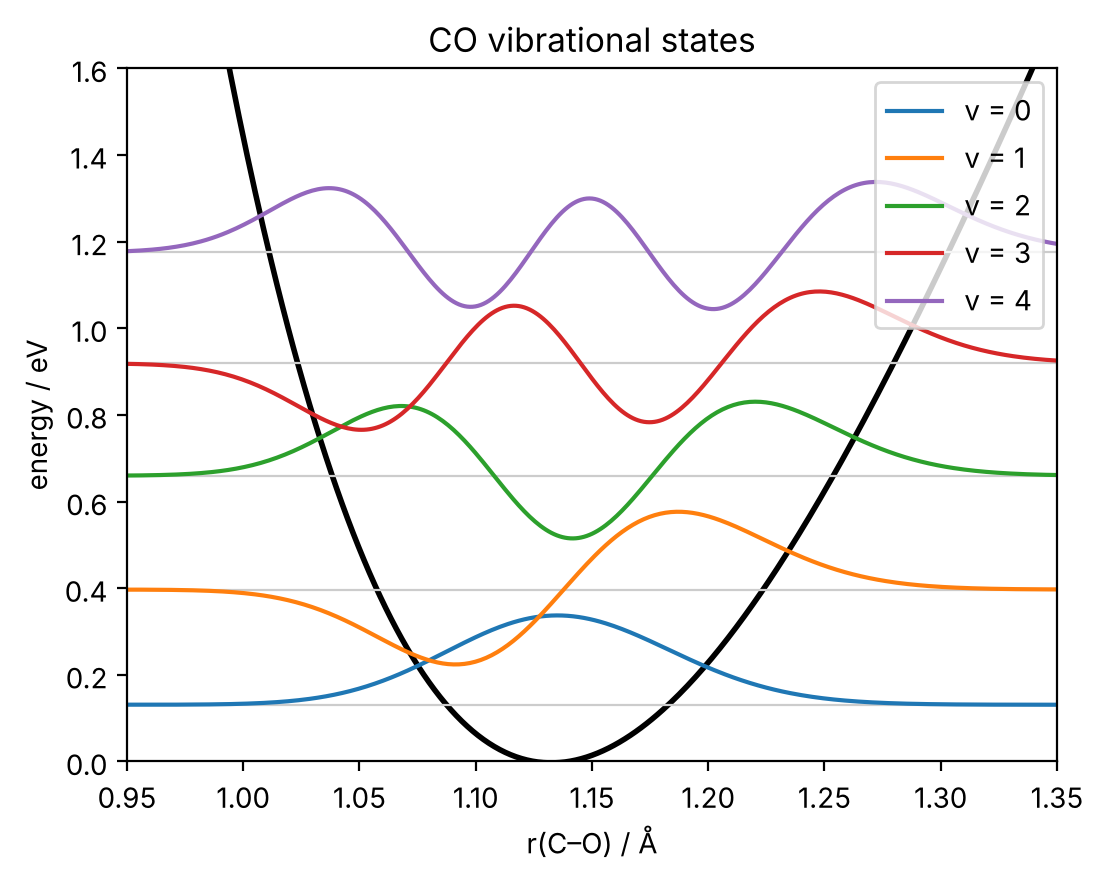

In [5]:
plt.figure(figsize=(6, 4.5))
plt.plot(r, V(r) - V_pts.min(), "k", lw=2)
for v in range(5):
    plt.axhline(E[v], color="0.8", lw=0.8)
    plt.plot(r, E[v] + 0.06 * psi[:, v] * np.sign(psi[np.argmax(np.abs(psi[:, v])), v]), label=f"v = {v}")
plt.ylim(0, 1.6); plt.xlim(0.95, 1.35)
plt.xlabel("r(C–O) / Å"); plt.ylabel("energy / eV"); plt.legend(loc="upper right"); plt.title("CO vibrational states")
plt.show()

**Question 2.** Where is the $v=0$ wavefunction largest, and where would a *classical* oscillator with the
same energy spend most of its time? How do the high-$v$ wavefunctions start to look more classical?

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

v = 0 peaks at r_e; a classical oscillator moves slowest, so spends most time, at the turning points. As v grows, |ψ|² builds up near the turning points (correspondence principle). The wavefunction also leaks past the turning points (tunnelling into the classically forbidden region). Asymmetry: the outer wall is softer, so the wavefunctions lean to longer r and ⟨r⟩ grows with v (why rotational constants B_v decrease with v).

</div>

## 4. Anharmonicity
The levels of an anharmonic oscillator fit

$$G(v) = \omega_e(v+\tfrac12) - \omega_e x_e (v+\tfrac12)^2,$$

so the fundamental is $\tilde\nu_{0\to1} = \omega_e - 2\omega_e x_e$.

**Exercise 3.** Fit $G(v)$ to your lowest five levels (`np.polyfit` in $v+\tfrac12$) and compare
$\omega_e$, $\omega_e x_e$ and the fundamental with experiment: $\omega_e$ = 2169.8, $\omega_e x_e$ = 13.29,
$\tilde\nu_{0\to1}$ = 2143.3 cm⁻¹.

In [6]:
vh = np.arange(5) + 0.5
c2, c1, c0 = np.polyfit(vh, E[:5] * lk.EV_TO_CM1, 2)
we, wexe = c1, -c2
print(f"omega_e     = {we:7.1f} cm^-1   (expt 2169.8)")
print(f"omega_e x_e = {wexe:7.2f} cm^-1   (expt 13.29)")
print(f"fundamental = {wn[1]:7.1f} cm^-1   (expt 2143.3)")

omega_e     =  2171.4 cm^-1   (expt 2169.8)
omega_e x_e =   12.99 cm^-1   (expt 13.29)
fundamental =  2145.4 cm^-1   (expt 2143.3)


## 5. Infrared intensities: fundamental and overtone

The strength of an absorption $0\to v$ is proportional to the square of the **transition dipole**

$$\langle 0|\mu|v\rangle = \int \psi_0(r)\,\mu(r)\,\psi_v(r)\,dr.$$

For a harmonic oscillator with a linear dipole, only $\Delta v = \pm1$ is allowed. Anharmonicity of the
potential (*mechanical*) and curvature of $\mu(r)$ (*electrical*) make the overtone $0\to2$ weakly allowed.

**Exercise 4.** Compute $|\langle 0|\mu|v\rangle|^2$ for $v$ = 1, 2, 3 with the B3LYP dipole curve
`mu_of_r`, and the ratio of the overtone to the fundamental.

In [7]:
h = r[1] - r[0]
M = np.array([np.sum(psi[:, 0] * mu_of_r(r) * psi[:, v]) * h for v in range(1, 4)])
for v, m in zip((1, 2, 3), M):
    print(f"|<0|mu|{v}>|^2 = {m**2:.3e} D^2   relative to 0->1: {m**2 / M[0]**2:.2e}")

|<0|mu|1>|^2 = 1.389e-02 D^2   relative to 0->1: 1.00e+00
|<0|mu|2>|^2 = 3.265e-05 D^2   relative to 0->1: 2.35e-03
|<0|mu|3>|^2 = 1.100e-07 D^2   relative to 0->1: 7.92e-06


**Question 4.** The integrated absorption of a band is proportional to $\tilde\nu\,|\langle 0|\mu|v\rangle|^2$. The CO overtone near
4260 cm⁻¹ is observed to be about 150 times weaker than the fundamental. How does your result compare? Why are overtones weak?

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

Overtones need either an anharmonic potential or a nonlinear dipole; both are small corrections near r_e, so the intensity is down by about two orders of magnitude. Reference run: |M₀₂|²/|M₀₁|² = 2.4×10⁻³, and with the factor ν̃₀₂/ν̃₀₁ ≈ 2 the overtone is ≈ 200 times weaker, the right order (experiment ≈ 1/150). The exact value is sensitive to the B3LYP dipole curvature, because the electrical and mechanical terms partly cancel. Other reference values: fundamental 2145.4 cm⁻¹ (expt 2143.3), ω_e x_e 13.0 (13.29), ¹³C shift −47.3 (−47.2), ZPE 1055 cm⁻¹.

</div>

## 6. Isotope shift
Isotopes change the mass but not the potential (Born–Oppenheimer). **Exercise 5.** Compute the
fundamental of ¹³C¹⁶O (mass of ¹³C: 13.003355 amu) and the shift from ¹²C¹⁶O.
Experiment: 2096.1 cm⁻¹ (shift −47.2 cm⁻¹). Compare with the harmonic prediction
$\tilde\nu \propto \mu^{-1/2}$.

In [8]:
mu13 = 13.003355 * m_O / (13.003355 + m_O)
_, E13, _ = vib_levels(V, mu13)
f13 = (E13[1] - E13[0]) * lk.EV_TO_CM1
print(f"13C16O fundamental = {f13:.1f} cm^-1, shift = {f13 - wn[1]:.1f} cm^-1")
print(f"harmonic estimate of the shift: {wn[1] * (np.sqrt(mu_CO / mu13) - 1):.1f} cm^-1")

13C16O fundamental = 2098.2 cm^-1, shift = -47.3 cm^-1
harmonic estimate of the shift: -47.8 cm^-1


## Looking ahead
This exact grid solution is easy in one dimension. A triatomic has 3N − 5 = 4 vibrations (linear) and a grid
of 600 points per coordinate would have $600^4 \approx 10^{11}$ points. In Notebooks 4–6 you will instead use
(1) the **harmonic** normal-mode approximation and (2) **classical molecular dynamics**, which costs little
in many dimensions but has no zero-point energy. Keep the zero-point energy from this notebook in mind for that comparison.